In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

from scipy.interpolate import griddata

In [2]:
## load map database
path_to_db = '/mnt/d/data/magnification_maps/masterlist.db'
db = sqlite3.connect(path_to_db)
## select maps
df = pd.read_sql_query("SELECT * FROM maps WHERE 1/((1-kappa)*(1-kappa) - gamma*gamma) > 0 AND kappa < 1.0 AND kappa > 0.0", db)

In [3]:
kappa_list = np.arange(0.1, 0.95, 0.01)
gamma_list = np.arange(0, 0.94, 0.01)
s_list     = np.arange(0, 100, 1)/100

In [4]:
s_list

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99])

In [23]:
np.unique(df[df['kappa']==0.33]['gamma'], return_counts=True)

(array([0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21, 0.22, 0.23, 0.24, 0.25,
        0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32, 0.33, 0.34, 0.35, 0.36,
        0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47,
        0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58,
        0.59, 0.6 , 0.61, 0.62, 0.63, 0.64]),
 array([12, 10, 10, 10, 10, 11, 11, 12, 11, 12, 12, 12, 12, 13, 15, 16, 12,
        14, 13, 16, 14, 12, 12, 12, 12, 12, 12, 13, 12, 11, 10, 11, 12, 12,
        11, 12, 12, 11, 11, 11, 12, 12, 12, 11, 12, 11, 12, 12, 11, 12]))

In [24]:
df[(df['kappa']==0.33) & (df['gamma']==0.3)].sort_values('s')

,index,id,kappa,gamma,s
3974,9286,11376,0.33,0.3,0.00
22261,52369,11377,0.33,0.3,0.10
13101,30777,11378,0.33,0.3,0.20
27244,64094,11379,0.33,0.3,0.30
24294,57162,11380,0.33,0.3,0.40
1886,4438,11381,0.33,0.3,0.50
9400,22120,11382,0.33,0.3,0.60
31960,75283,11383,0.33,0.3,0.70
25355,59674,11384,0.33,0.3,0.80
14998,35255,11385,0.33,0.3,0.90


In [ ]:
Nbins = 200
Nmaps = len(df)

data = np.zeros((Nbins, len(kappa_list), len(gamma_list), len(s_list)))
data[:] = np.nan

In [19]:
Nbins = 200
Nmaps = len(df)

points = np.zeros((Nbins*Nmaps, 4))
values = np.zeros(Nbins*Nmaps)

for i, row in df.iterrows():
    mapid = int(row['id'])
    kappa = row['kappa']
    gamma = row['gamma']
    s = row['s']
    
    mu, p_mu = np.loadtxt('/mnt/d/data/imf_with_doubles/test/' + str(mapid) +'.dat').T
    log10_mu = np.log10(mu)
    
    points[Nbins*i:Nbins*(i+1), 0] = log10_mu
    points[Nbins*i:Nbins*(i+1), 1:] = np.asarray([kappa, gamma, s])
    
    values[Nbins*i:Nbins*(i+1)] = p_mu

In [ ]:
new_kappa = 0.4
new_gamma = 0.4
new_s     = 0.56

#new_points = np.vstack([log10_mu, np.repeat(np.asarray([new_kappa, new_s])[:,np.newaxis], Nbins, axis=1)]).T
new_points = np.vstack([log10_mu, np.repeat(np.asarray([new_kappa, new_gamma, new_s])[:,np.newaxis], Nbins, axis=1)]).T
new_values = griddata(points, values, new_points, method='linear')

In [18]:
## load Luke's mpds
kappa = new_kappa
gamma = new_gamma
s = new_s

mu_macro = 1 / ((1 - kappa)**2 - gamma**2)

filename = 'k_' + str(kappa) + '_y_' + str(gamma) + '_s_' + str(s) + '.npy'

#log_mu, p_log_mu = np.load('/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/k_0.38_y_0.38_s_0.96.npy').T
log_mu, p_log_mu = np.load('/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/' + filename).T
## normalize p
p_log_mu = p_log_mu / np.sum(p_log_mu)
## normalize to mu_macro
log_mu = log_mu  - np.log10(mu_macro)

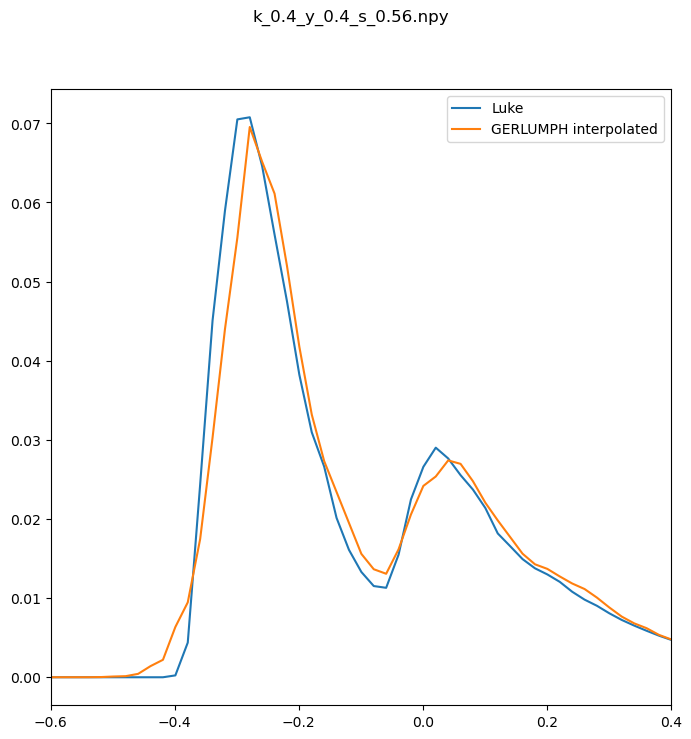

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

fig.suptitle(filename)

ax.plot(log_mu, p_log_mu, label='Luke')

ax.plot(new_points[:,0], new_values, label='GERLUMPH interpolated')

ax.legend()
ax.set_xlim(-0.6, 0.4);